# scikit-learn: Anomaly Detection on Network Intrusion Data

I tested scikit-learn's `IsolationForest` and `EllipticEnvelope` on network traffic provided by the KDD Cup 1999 intrusion detection dataset. Both catch attacks almost perfectly, but so does measuring single features through 'src_bytes', which says more about the age and easiness of the benchmark rather than the detectors. Futhermore, `EllipticEnvelope` throws thousands of warnings that a determinant increased during a step that is guaranteed to decrease it, because 99.3% of connections have the same duration and its covariance matrices become nearly singular.

This notebook runs in Julia and calls scikit-learn through PythonCall.jl, which installs its own copy of Python and scikit-learn the first time it runs.

In [1]:
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99
from sklearn.covariance import EllipticEnvelope
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

## What scikit-learn is and why I picked it

scikit-learn is a machine learning library for Python, built on NumPy and SciPy. I picked it to continue my first exploration on detecting attacks in network traffic, and because anomaly detection puts class topics like conditioning and the bias-variance tradeoff into a security setting. I focused on two detectors.

* **IsolationForest** isolates points with random splits. Anomalies end up close to the root of each tree.
* **EllipticEnvelope** fits a robust covariance matrix with the Minimum Covariance Determinant (MCD) algorithm and flags points far from the center.

## The community

scikit-learn started in 2007 and has about 3,500 contributors, 195 of them active in the past year. It averages about 19 commits and 50 new issues and pull requests per week. Development happens in GitHub issues and pull requests, and the project has a strict AI policy that bans fully automated pull requests.

## The data

`fetch_kddcup99(subset="http")` gives HTTP connections labeled as normal or attack. Each feature is stored as log(x + 0.1) so byte counts spanning many orders of magnitude don't dominate.

In [2]:
data = fetch_kddcup99(subset="http", random_state=42)
X = data.data.astype(float)
y = (data.target != b"normal.").astype(int)

print(X.shape, y.sum())
print(X[y == 0].mean(axis=0))
print(X[y == 1].mean(axis=0))
print(np.mean(X[:, 0] == np.log(0.1)))

(58725, 3) 2209
[-2.2653564   5.53489987  7.48172175]
[-2.22449987 10.87388235  8.99890371]
0.993205619412516


The output shows the data shape and number of attacks, then the average duration, src_bytes, and dst_bytes for normal and attack connections, then the fraction of connections with a duration of exactly zero. A typical attack connection sent roughly e^5.3, about 200 times more source bytes than a typical normal one. Nearly every connection has a duration of exactly zero, which means the duration feature has almost no variance. This matters for `EllipticEnvelope`, because the covariance matrices it builds become nearly singular when one feature barely changes.

In [3]:
iforest = IsolationForest(random_state=42).fit(X)
print(roc_auc_score(y, -iforest.score_samples(X)))
print(roc_auc_score(y, X[:, 1]))

0.9940349641909455
0.9972855249474697


A one line rule nearly matches the detector, so KDD99 appears to be an easy benchmark. Take that as you will, but it makes this project a great starting point.

## Accuracy versus cost in IsolationForest

The main knob in `IsolationForest` is the number of trees. Each setting is run with 5 random seeds.

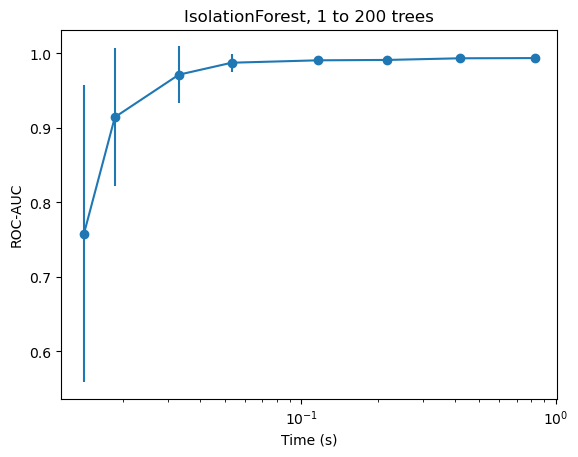

In [4]:
tree_counts = [1, 2, 5, 10, 25, 50, 100, 200]
mean_auc, std_auc, mean_time = [], [], []

for n in tree_counts:
    aucs, times = [], []
    for seed in range(5):
        start = time.perf_counter()
        m = IsolationForest(n_estimators=n, random_state=seed).fit(X)
        aucs.append(roc_auc_score(y, -m.score_samples(X)))
        times.append(time.perf_counter() - start)
    mean_auc.append(np.mean(aucs))
    std_auc.append(np.std(aucs))
    mean_time.append(np.mean(times))

plt.errorbar(mean_time, mean_auc, yerr=std_auc, marker="o")
plt.xscale("log")
plt.xlabel("Time (s)")
plt.ylabel("ROC-AUC")
plt.title("IsolationForest, 1 to 200 trees")
plt.show()

With one tree the AUC averages about 0.76 but swings by about 0.20 between seeds. By 25 trees it reaches about 0.99 and barely moves after that. Going from 25 to 200 trees takes about 8 times as long for only about 0.003 more AUC, though the spread across seeds shrinks by about a factor of 10. Extra trees buy repeatability rather than accuracy, which is the variance side of the bias-variance tradeoff. scikit-learn's default of 100 trees is well past the point of diminishing returns here.

## Where the numerics break in EllipticEnvelope

MCD repeatedly picks the most tightly packed subset of the data and recomputes its covariance, and each step is guaranteed to shrink the determinant. Below, the warnings scikit-learn raises are counted instead of printed.

0.999302328435193 30.757074094974385
0.9993026888854848 39.398365769497566


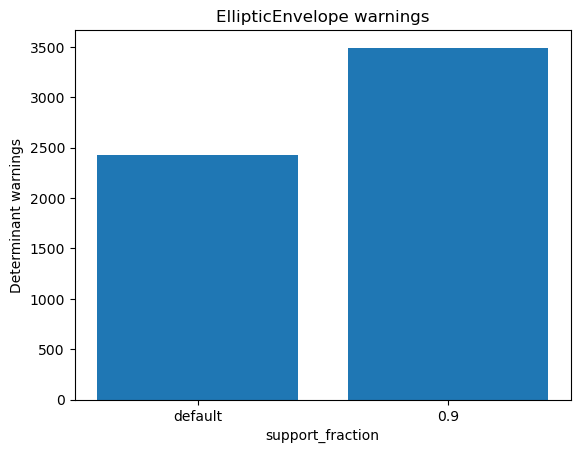

In [5]:
warning_counts = []

for frac in [None, 0.9]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        ee = EllipticEnvelope(random_state=42, support_fraction=frac).fit(X)
    warning_counts.append(sum("Determinant has increased" in str(w.message) for w in caught))
    print(roc_auc_score(y, -ee.score_samples(X)), np.linalg.cond(ee.covariance_))

plt.bar(["default", "0.9"], warning_counts)
plt.xlabel("support_fraction")
plt.ylabel("Determinant warnings")
plt.title("EllipticEnvelope warnings")
plt.show()

Since nearly all durations are identical, the subsets MCD picks have almost no variance in that feature, their covariance matrices are nearly singular. A covariance matrix is built like XᵀX, so like the normal equations it squares the conditioning of the data. With a determinant close to zero, floating point rounding takes over and the guarantee breaks. Raising `support_fraction` to 0.9 made it worse, likely because 90% of the data still fits inside the zero-duration block.

Still, the final covariance matrices are well conditioned and the AUC is about 0.999, so the instability stays in the intermediate steps.

## Questions about the software

* Why does `EllipticEnvelope` raise thousands of warnings suggesting a higher `support_fraction`, instead of one warning that a feature is nearly constant, when raising it made things worse here?
* Possible question to explore, would these detectors still look this good on modern intrusion data like CIC-IDS2017?

## Proposed group experiment

Sweep `support_fraction` from 0.5 to 1.0 on KDD99 and a possibly more modern dataset, recording warning counts, covariance condition numbers, and ROC-AUC.